# Corrected DNS feature-selection experiment

Search candidates are fitted on a training subsample and scored ONLY on a validation subsample. The existing test partition is used for final evaluation, never fitness scoring. This repairs the direct test-sampling overlap; it does not audit upstream split independence or undo previous inspection of test results.

## Requirements
Place this notebook beside `Enhanced_detection.py` and six numeric cached arrays: `x_train.npy`, `y_train.npy`, `x_val.npy`, `y_val.npy`, `x_test.npy`, `y_test.npy`. The original CSV extraction is not repeated. The imported EnhancedBinaryRLGWO implementation remains an external dependency and has not been audited here.

Run cells in order. Searches and full-data training are expensive. Outputs go to a NEW experiment directory. Completed configurations can be reloaded without retraining. No old selected indices or timing measurements are reused.

If needed, install in a separate cell: `%pip install numpy pandas scipy scikit-learn xgboost matplotlib tqdm torch`.


**What this cell does:** Imports libraries, sets the root folder, run folder, random seeds and search settings.

In [ ]:
from pathlib import Path
import json, random, time, gc, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from scipy.stats import chi2, binomtest
from itertools import combinations
from xgboost import XGBClassifier

ROOT = Path.cwd()
RUN_DIR = ROOT / 'validation_only_run_v1'
RUN_DIR.mkdir(exist_ok=True)
FIG_DIR = RUN_DIR / 'figures'
FIG_DIR.mkdir(exist_ok=True)
SEED = 42
POP_SIZE, GENERATIONS = 40, 15
N_SEARCH_TRAIN, N_SEARCH_VAL = 500_000, 150_000
MIN_FEATURES, MAX_FEATURES, IDEAL = 8, 10, 9
PENALTY = 0.002
SEARCH_JOBS = 1
feature_names = ['len','subdomains_count','w_count','w_max','entropy',
'w_max_ratio','w_count_ratio','digits_ratio','uppercase_ratio','time_avg',
'time_stdev','size_avg','size_stdev','throughput','unique','entropy_avg','entropy_stdev']

def seed_everything():
    random.seed(SEED)
    np.random.seed(SEED)
    try:
        import torch
        torch.manual_seed(SEED)
    except ImportError:
        pass

def slug(name):
    return name.lower().replace(' ', '_')


## 1. Load existing numeric arrays without duplicating full matrices

**What this cell does:** Loads the saved train, validation and test `.npy` arrays from disk (without copying them).

In [ ]:
arrays = {}
for name in ['x_train','y_train','x_val','y_val','x_test','y_test']:
    path = ROOT / f'{name}.npy'
    if not path.exists():
        raise FileNotFoundError(f'Missing {path.name}: run your original extraction/cache step first.')
    arrays[name] = np.load(path, mmap_mode='r', allow_pickle=False)
x_train, y_train = arrays['x_train'], arrays['y_train']
x_val, y_val = arrays['x_val'], arrays['y_val']
x_test, y_test = arrays['x_test'], arrays['y_test']
for split in ['train','val','test']:
    X, y = arrays[f'x_{split}'], arrays[f'y_{split}']
    assert X.ndim == 2 and X.shape[1] == 17
    assert y.ndim == 1 and len(X) == len(y)
    assert set(np.unique(y)) == {0,1}
    print(split, X.shape, np.unique(y, return_counts=True))


train (24581517, 17) (array([0, 1]), array([24429561,   151956], dtype=int64))
val (3511645, 17) (array([0, 1]), array([3489937,   21708], dtype=int64))
test (7023290, 17) (array([0, 1]), array([6979874,   43416], dtype=int64))


## 2. Training and VALIDATION search samples
The test arrays are not referenced in this sampling or the fitness function. Saved indices are relative to their respective original partitions.

**What this cell does:** Draws the stratified training and validation samples used only for the optimiser searches. The test set is not touched.

In [ ]:
train_idx, _ = train_test_split(np.arange(len(y_train)), train_size=N_SEARCH_TRAIN,
    stratify=y_train, random_state=SEED)
val_idx, _ = train_test_split(np.arange(len(y_val)), train_size=N_SEARCH_VAL,
    stratify=y_val, random_state=SEED)
X_search_train, y_search_train = np.asarray(x_train[train_idx]), np.asarray(y_train[train_idx])
X_search_val, y_search_val = np.asarray(x_val[val_idx]), np.asarray(y_val[val_idx])
np.save(RUN_DIR / 'search_training_indices.npy', train_idx)
np.save(RUN_DIR / 'search_validation_indices.npy', val_idx)
print(X_search_train.shape, X_search_val.shape)


(500000, 17) (150000, 17)


## 3. Optimiser implementations
ACO and PSO definitions are retained from the supplied notebook. Enhanced RLGWO is imported from your original module, not replaced by the different phase2 class.

**What this cell does:** Loads the Enhanced RLGWO optimiser from `Enhanced_detection.py`, which must sit next to this notebook.

In [ ]:
module_path = ROOT / 'Enhanced_detection.py'
if not module_path.exists():
    raise FileNotFoundError('Place your original Enhanced_detection.py beside this notebook.')
spec = importlib.util.spec_from_file_location('enhanced_detection', module_path)
enhanced_detection = importlib.util.module_from_spec(spec)
spec.loader.exec_module(enhanced_detection)
EnhancedBinaryRLGWO = enhanced_detection.EnhancedBinaryRLGWO
# Legacy module names hold validation data during search, NOT test data.
enhanced_detection.X_train_all = X_search_train
enhanced_detection.y_train_all = y_search_train
enhanced_detection.X_test_all = X_search_val
enhanced_detection.y_test_all = y_search_val


**What this cell does:** Defines `BinaryACO` (ant colony feature selection, adapted from Talabani et al. 2025).

In [ ]:
import numpy as np
from tqdm import tqdm

class BinaryACO:
    """
    ACO feature selection adapted for this project (17-feature DNS
    exfiltration dataset, evaluate_features_fast fitness), following the
    core probability/pheromone equations from:

    Talabani, H.S.; Abdul, Z.K.; Mohammed Saleh, H.M. (2025). "DNS over
    HTTPS Tunneling Detection System Based on Selected Features via Ant
    Colony Optimization." Future Internet, 17, 211.
    https://doi.org/10.3390/fi17050211

    Adaptations made for this project:
    - Interface matches BinaryRLGWO / EnhancedBinaryRLGWO / BinaryPSO:
      __init__(n_dimensions, population_size, generations).run(evaluate_func)
    - Fitness function is evaluate_features_fast (weighted F1 - feature
      count penalty), not raw accuracy as in the original paper.
    - population_size/generations reduced from the paper's 30 ants /
      500 iterations to match this project's compute budget (24.5M-row
      dataset); paper's original values kept as commented defaults.
    - Reinforcement rule corrected to Delta_T_i^k = rho * f(S_k), so that
      higher-fitness subsets receive MORE pheromone, consistent with the
      paper's own stated intent ("subsets with higher accuracies are
      favored" / "features ... receive greater reinforcement"). The
      paper's literal published equation (rho / f(S_k)) would do the
      opposite and is treated here as a likely typo in the source PDF.
    """

    def __init__(self, n_dimensions, population_size, generations,
                 evaporation_rate=0.5, alpha=1.0, beta=1.0, heuristic=None):
        self.n_dimensions = n_dimensions
        self.population_size = population_size   # "number of ants" (paper default: 30)
        self.generations = generations            # "iterations" (paper default: 500)
        self.rho = evaporation_rate                # paper default: 0.5
        self.alpha = alpha                         # pheromone importance factor, paper default: 1
        self.beta = beta                           # heuristic importance factor
        # Heuristic value eta_i per feature. No feature-specific heuristic is
        # defined in the paper beyond pheromone, so default to uniform (1.0)
        # for every feature, which reduces the rule to pure pheromone-guided
        # selection when beta has no extra information source.
        self.heuristic = heuristic if heuristic is not None else np.ones(n_dimensions)

    def _construct_subset(self, pheromone):
        """
        Builds one ant's feature subset using the paper's probability rule:
            P_i(t) = [T_i(t)^alpha * eta_i^beta] / sum_{j in NotYet} [T_j(t)^alpha * eta_j^beta]
        Ants pick a random subset size each time (paper does not fix subset
        size), but always end with at least 1 feature selected.
        """
        not_yet = list(range(self.n_dimensions))
        subset = []
        size = np.random.randint(1, self.n_dimensions + 1)

        for _ in range(size):
            if not not_yet:
                break
            weights = np.array([
                (pheromone[i] ** self.alpha) * (self.heuristic[i] ** self.beta)
                for i in not_yet
            ])
            weights = np.clip(weights, 1e-12, None)  # avoid all-zero weights
            probs = weights / weights.sum()
            chosen = np.random.choice(not_yet, p=probs)
            subset.append(chosen)
            not_yet.remove(chosen)

        individual = np.zeros(self.n_dimensions, dtype=int)
        individual[subset] = 1
        return individual

    def run(self, evaluate_func):
        pheromone = np.ones(self.n_dimensions)
        best_individual_so_far, best_fitness_so_far = None, -np.inf
        history = []

        progress_bar = tqdm(range(1, self.generations + 1), desc="Binary ACO (Talabani et al. 2025, adapted)")
        for gen in progress_bar:
            population = np.array([self._construct_subset(pheromone) for _ in range(self.population_size)])
            fitnesses = np.array([evaluate_func(ind.tolist())[0] for ind in population])

            gen_best_idx = np.argmax(fitnesses)
            if fitnesses[gen_best_idx] > best_fitness_so_far:
                best_fitness_so_far = fitnesses[gen_best_idx]
                best_individual_so_far = population[gen_best_idx].copy()

            # Evaporation: T_i(t+1) = (1 - rho) * T_i(t)
            pheromone = (1 - self.rho) * pheromone

            # Reinforcement (corrected direction): Delta_T_i^k = rho * f(S_k) if F_i in S_k else 0
            for ind, fit in zip(population, fitnesses):
                fit_clamped = max(fit, 0.0)
                pheromone += (self.rho * fit_clamped) * ind

            history.append(best_fitness_so_far)
            progress_bar.set_postfix(
                best_fitness=f"{best_fitness_so_far:.4f}",
                features=f"{int(best_individual_so_far.sum())}"
            )

        return best_individual_so_far.tolist(), best_fitness_so_far, history

**What this cell does:** Defines `BinaryPSO` (binary particle swarm feature selection, adapted from the IJCSNS 2014 paper).

In [ ]:
import numpy as np
from tqdm import tqdm

class BinaryPSO:
    """
    Binary PSO for feature selection, adapted for this project.

    Core equations follow:
    "Intrusion Feature Selection Algorithm Based on Particle Swarm
    Optimization." International Journal of Computer Science and
    Network Security (IJCSNS), 2014.
    http://paper.ijcsns.org/07_book/201412/20141208.pdf

    Velocity update (Eq. 3):
        v_id(n+1) = w*v_id(n) + c1*r1*(p_id - x_id(n)) + c2*r2*(p_gd - x_id(n))
    Sigmoid transfer (Eq. 5):
        s(v) = 1 / (1 + exp(-v))
    Position update (Eq. 6):
        if rand() < s(v_id(n)) then x_id(n+1) = 1 else x_id(n+1) = 0

    Adaptations for this project:
    - Interface matches BinaryRLGWO / EnhancedBinaryRLGWO / BinaryACO:
      __init__(n_dimensions, population_size, generations).run(evaluate_func)
    - Fitness function is evaluate_features_fast (weighted F1 minus a
      feature-count penalty), consistent with the other optimizers used
      in this study, rather than the paper's own fitness formula.
    - V_max included (paper mentions restraining velocity to avoid x_i
      permanently locking at 0 or 1); default set empirically to 6.0.
    """

    def __init__(self, n_dimensions, population_size, generations,
                 w=0.9, c1=0.5, c2=0.3, v_max=6.0):
        # w, c1, c2 defaults taken from a closely related PSO-IDS study
        # (Kunhare & Tiwari) reporting best accuracy with C1=0.5, C2=0.3, W=0.9
        self.n_dimensions = n_dimensions
        self.population_size = population_size
        self.generations = generations
        self.w, self.c1, self.c2 = w, c1, c2
        self.v_max = v_max

    @staticmethod
    def _sigmoid(v):
        return 1 / (1 + np.exp(-v))

    def run(self, evaluate_func):
        # Step 2: random colony, random velocities
        pos = np.random.randint(0, 2, (self.population_size, self.n_dimensions)).astype(float)
        vel = np.zeros((self.population_size, self.n_dimensions))  # paper: velocity initialized to zero

        fitnesses = np.array([evaluate_func(p.astype(int).tolist())[0] for p in pos])
        pbest_pos = pos.copy()
        pbest_fit = fitnesses.copy()
        gbest_idx = np.argmax(fitnesses)
        gbest_pos = pos[gbest_idx].copy()
        gbest_fit = fitnesses[gbest_idx]
        history = [gbest_fit]

        progress_bar = tqdm(range(1, self.generations + 1), desc="Binary PSO (IJCSNS 2014, adapted)")
        for gen in progress_bar:
            r1, r2 = np.random.rand(*pos.shape), np.random.rand(*pos.shape)

            # Step 6: velocity update (Eq. 3)
            vel = (self.w * vel
                   + self.c1 * r1 * (pbest_pos - pos)
                   + self.c2 * r2 * (gbest_pos - pos))
            vel = np.clip(vel, -self.v_max, self.v_max)

            # Position update via sigmoid (Eq. 5, 6)
            s = self._sigmoid(vel)
            pos = (np.random.rand(*pos.shape) < s).astype(float)

            for i in range(self.population_size):
                if pos[i].sum() == 0:
                    pos[i, np.random.randint(self.n_dimensions)] = 1

            # Step 3: evaluate fitness
            fitnesses = np.array([evaluate_func(p.astype(int).tolist())[0] for p in pos])

            # Step 4: update pbest
            improved = fitnesses > pbest_fit
            pbest_pos[improved] = pos[improved]
            pbest_fit[improved] = fitnesses[improved]

            # Step 5: update gbest
            if fitnesses.max() > gbest_fit:
                gbest_fit = fitnesses.max()
                gbest_pos = pos[np.argmax(fitnesses)].copy()

            history.append(gbest_fit)
            progress_bar.set_postfix(best_fitness=f"{gbest_fit:.4f}", features=f"{int(gbest_pos.sum())}")

        # Step 8: return optimal feature subset
        return gbest_pos.astype(int).tolist(), gbest_fit, history

## 4. Single fitness definition
Preserves weighted F1 - FPR - 0.002 × |k-9|, with 8–10 allowed features. Weighted F1 is majority-weighted, not attack-class F1. The tuple return matches the original optimiser callback interface.

**What this cell does:** Defines the one fitness function used by all optimisers: weighted F1 minus FPR minus a penalty for deviating from 9 features (8-10 allowed).

In [ ]:
def evaluate_features_fast(individual):
    mask = np.asarray(individual)
    if mask.shape != (17,) or not np.all(np.isin(mask, [0,1])):
        raise ValueError('Expected a binary mask of length 17.')
    idx = np.flatnonzero(mask)
    k = len(idx)
    if not MIN_FEATURES <= k <= MAX_FEATURES:
        return (0.0,)
    clf = RandomForestClassifier(n_estimators=50, random_state=SEED, n_jobs=SEARCH_JOBS)
    clf.fit(X_search_train[:,idx], y_search_train)
    prediction = clf.predict(X_search_val[:,idx])
    score = f1_score(y_search_val, prediction, average='weighted', zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_search_val, prediction, labels=[0,1]).ravel()
    fpr = fp / (fp + tn)
    return (float(score - fpr - PENALTY * abs(k - IDEAL)),)

enhanced_detection.evaluate_features_fast = evaluate_features_fast

def run_search(name, optimiser_class):
    seed_everything()
    optimiser = optimiser_class(17, POP_SIZE, GENERATIONS)
    start = time.perf_counter()
    solution, fitness, history = optimiser.run(evaluate_features_fast)
    seconds = time.perf_counter() - start
    mask = np.asarray(solution, dtype=int)
    idx = np.flatnonzero(mask)
    if mask.shape != (17,) or not MIN_FEATURES <= len(idx) <= MAX_FEATURES or fitness <= 0:
        raise ValueError('Search did not return an admissible positive-fitness solution.')
    record = dict(name=name, selected_indices=idx.tolist(), best_fitness=float(fitness),
        history=[float(v) for v in history], search_seconds=seconds,
        search_evaluation_partition='validation')
    (RUN_DIR / f'{slug(name)}_search.json').write_text(json.dumps(record, indent=2))
    print(record)
    del optimiser
    gc.collect()
    return record


## 5. Run searches separately
These cells rerun searches. To resume an existing run, skip them and use the loading cell below. Change RUN_DIR for a new experiment rather than overwriting results.

**What this cell does:** Runs the ACO search and saves it to the run folder.

In [ ]:
search_aco = run_search('ACO', BinaryACO)

Binary ACO (Talabani et al. 2025, adapted): 100%|██████████| 15/15 [1:02:27<00:00, 249.82s/it, best_fitness=0.9999, features=9]


{'name': 'ACO', 'selected_indices': [0, 2, 4, 6, 7, 9, 10, 12, 13], 'best_fitness': 0.9999264816483772, 'history': [0.9999264816483772, 0.9999264816483772, 0.9999264816483772, 0.9999264816483772, 0.9999264816483772, 0.9999264816483772, 0.9999264816483772, 0.9999264816483772, 0.9999264816483772, 0.9999264816483772, 0.9999264816483772, 0.9999264816483772, 0.9999264816483772, 0.9999264816483772, 0.9999264816483772], 'search_seconds': 3747.326897299994, 'search_evaluation_partition': 'validation'}


**What this cell does:** Runs the PSO search and saves it to the run folder.

In [ ]:
search_pso = run_search('PSO', BinaryPSO)

Binary PSO (IJCSNS 2014, adapted): 100%|██████████| 15/15 [2:42:52<00:00, 651.48s/it, best_fitness=1.0000, features=9] 


{'name': 'PSO', 'selected_indices': [0, 1, 3, 6, 7, 8, 12, 14, 15], 'best_fitness': 0.9999532489022119, 'history': [0.9999265031324365, 0.9999265031324365, 0.9999331931210388, 0.9999331931210388, 0.9999331931210388, 0.9999331931210388, 0.9999331931210388, 0.9999331931210388, 0.9999532489022119, 0.9999532489022119, 0.9999532489022119, 0.9999532489022119, 0.9999532489022119, 0.9999532489022119, 0.9999532489022119, 0.9999532489022119], 'search_seconds': 10396.354519099987, 'search_evaluation_partition': 'validation'}


**What this cell does:** Runs the Enhanced RLGWO search and saves it to the run folder.

In [ ]:
search_enhanced_rlgwo = run_search('Enhanced RLGWO', EnhancedBinaryRLGWO)

Enhanced RLGWO:   0%|          | 0/15 [00:00<?, ?it/s]

{'name': 'Enhanced RLGWO', 'selected_indices': [0, 1, 2, 7, 10, 12, 13, 14, 15], 'best_fitness': 0.9999331931210388, 'history': [0.9998863843881126, 0.9998931063875871, 0.9998931063875871, 0.9998931063875871, 0.9999265031324365, 0.9999265031324365, 0.9999265031324365, 0.9999265031324365, 0.9999331788835819, 0.9999331788835819, 0.9999331788835819, 0.9999331788835819, 0.9999331788835819, 0.9999331931210388, 0.9999331931210388, 0.9999331931210388], 'search_seconds': 10597.917919899977, 'search_evaluation_partition': 'validation'}


**What this cell does:** Loads the saved search results and builds the feature-subset configurations. Use this instead of re-running the searches.

In [ ]:
search_results = {}
for name in ['ACO','PSO','Enhanced RLGWO']:
    search_results[name] = json.loads((RUN_DIR / f'{slug(name)}_search.json').read_text())
configs = {'Baseline': list(range(17))}
configs.update({name: result['selected_indices'] for name,result in search_results.items()})
print(configs)


{'Baseline': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16], 'ACO': [0, 2, 4, 6, 7, 9, 10, 12, 13], 'PSO': [0, 1, 3, 6, 7, 8, 12, 14, 15], 'Enhanced RLGWO': [0, 1, 2, 7, 10, 12, 13, 14, 15]}


## 6. Full-data evaluation and immediate persistence
Training and inference timings are measured on THESE fits, not an older XGBoost setup. Feature slicing is excluded from fit timing; prediction timing is batch prediction only. Single runs do not establish timing variability. Full-data training may still exceed available RAM. Models and slices are released sequentially.

**What this cell does:** Defines `validate_subset`: trains XGBoost and Random Forest on a subset, times training and prediction, and saves predictions and confusion matrices.

In [ ]:
def validate_subset(name, selected_idx):
    result = {}
    for key in ['xgb','rf']:
        Xtr = x_train[:,selected_idx]
        if key == 'xgb':
            Xv = x_val[:,selected_idx]
            clf = XGBClassifier(objective='binary:logistic', n_estimators=100,
                subsample=0.1, scale_pos_weight=1, eval_metric='error',
                early_stopping_rounds=10, n_jobs=4, random_state=SEED)
            start = time.perf_counter()
            clf.fit(Xtr, y_train, eval_set=[(Xv,y_val)], verbose=False)
            train_seconds = time.perf_counter() - start
            del Xv
        else:
            clf = RandomForestClassifier(n_estimators=5, max_depth=20,
                class_weight=None, n_jobs=1, random_state=SEED)
            start = time.perf_counter()
            clf.fit(Xtr,y_train)
            train_seconds = time.perf_counter() - start
        del Xtr
        Xt = x_test[:,selected_idx]
        start = time.perf_counter()
        prediction = clf.predict(Xt)
        inference_seconds = time.perf_counter() - start
        cm = confusion_matrix(y_test,prediction,labels=[0,1])
        report = classification_report(y_test,prediction,output_dict=True,zero_division=0)
        stem = f'{slug(name)}_{key}'
        np.save(RUN_DIR / f'{stem}_prediction.npy',prediction)
        np.save(RUN_DIR / f'{stem}_cm.npy',cm)
        info = dict(report=report, train_seconds=train_seconds, inference_seconds=inference_seconds,
                    selected_indices=selected_idx, parameters=clf.get_params())
        if key == 'xgb': info['best_iteration'] = int(clf.best_iteration)
        (RUN_DIR / f'{stem}_evaluation.json').write_text(json.dumps(info,indent=2))
        result[key] = dict(cm=cm,report=report,y_pred=prediction)
        print(name,key,classification_report(y_test,prediction,digits=4,zero_division=0))
        del clf,Xt
        gc.collect()
    return result

preds = {}


**What this cell does:** Evaluates the baseline (all 17 features).

In [ ]:
preds['Baseline'] = validate_subset('Baseline', configs['Baseline'])

Baseline xgb               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   6979874
           1     0.9973    0.9967    0.9970     43416

    accuracy                         1.0000   7023290
   macro avg     0.9987    0.9983    0.9985   7023290
weighted avg     1.0000    1.0000    1.0000   7023290

Baseline rf               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   6979874
           1     0.9996    0.9985    0.9990     43416

    accuracy                         1.0000   7023290
   macro avg     0.9998    0.9992    0.9995   7023290
weighted avg     1.0000    1.0000    1.0000   7023290



**What this cell does:** Evaluates the ACO subset.

In [ ]:
preds['ACO'] = validate_subset('ACO', configs['ACO'])

ACO xgb               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   6979874
           1     0.9958    0.9952    0.9955     43416

    accuracy                         0.9999   7023290
   macro avg     0.9979    0.9976    0.9977   7023290
weighted avg     0.9999    0.9999    0.9999   7023290

ACO rf               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   6979874
           1     0.9991    0.9953    0.9972     43416

    accuracy                         1.0000   7023290
   macro avg     0.9995    0.9976    0.9986   7023290
weighted avg     1.0000    1.0000    1.0000   7023290



**What this cell does:** Evaluates the PSO subset.

In [ ]:
preds['PSO'] = validate_subset('PSO', configs['PSO'])

PSO xgb               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   6979874
           1     0.9985    0.9958    0.9972     43416

    accuracy                         1.0000   7023290
   macro avg     0.9993    0.9979    0.9986   7023290
weighted avg     1.0000    1.0000    1.0000   7023290

PSO rf               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   6979874
           1     0.9994    0.9964    0.9979     43416

    accuracy                         1.0000   7023290
   macro avg     0.9997    0.9982    0.9990   7023290
weighted avg     1.0000    1.0000    1.0000   7023290



**What this cell does:** Evaluates the Enhanced RLGWO subset.

In [ ]:
preds['Enhanced RLGWO'] = validate_subset('Enhanced RLGWO', configs['Enhanced RLGWO'])

Enhanced RLGWO xgb               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   6979874
           1     0.9983    0.9972    0.9978     43416

    accuracy                         1.0000   7023290
   macro avg     0.9991    0.9986    0.9989   7023290
weighted avg     1.0000    1.0000    1.0000   7023290

Enhanced RLGWO rf               precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000   6979874
           1     0.9994    0.9973    0.9983     43416

    accuracy                         1.0000   7023290
   macro avg     0.9997    0.9986    0.9992   7023290
weighted avg     1.0000    1.0000    1.0000   7023290



## 7. Reload completed evaluation outputs
This cell also works after a restart once the imports and arrays have been loaded. It never retrains.

**What this cell does:** Reloads the saved predictions, confusion matrices and timings, then builds the metrics and timing tables.

In [ ]:
preds = {}
metric_rows, timing_rows = [], []
for name in configs:
    preds[name] = {}
    for key, classifier in [('xgb','XGBoost'),('rf','Random Forest')]:
        stem = f'{slug(name)}_{key}'
        info = json.loads((RUN_DIR / f'{stem}_evaluation.json').read_text())
        cm = np.load(RUN_DIR / f'{stem}_cm.npy')
        prediction = np.load(RUN_DIR / f'{stem}_prediction.npy', mmap_mode='r')
        assert prediction.shape == y_test.shape
        assert np.array_equal(cm,confusion_matrix(y_test,prediction,labels=[0,1]))
        preds[name][key] = dict(cm=cm,report=info['report'],y_pred=prediction)
        tn,fp,fn,tp = cm.ravel()
        metric_rows.append(dict(Configuration=name,Classifier=classifier,Key=key,
            Precision=tp/(tp+fp) if tp+fp else 0,Recall=tp/(tp+fn),
            F1=2*tp/(2*tp+fp+fn),FPR_percent=100*fp/(fp+tn),
            TN=int(tn),FP=int(fp),FN=int(fn),TP=int(tp)))
        timing_rows.append(dict(Configuration=name,Key=key,
            Training=info['train_seconds'],Inference=info['inference_seconds']))
metrics_df = pd.DataFrame(metric_rows)
timing_df = pd.DataFrame(timing_rows)
metrics_df.to_csv(RUN_DIR / 'metrics.csv',index=False)
timing_df.to_csv(RUN_DIR / 'timings.csv',index=False)
display(metrics_df)


,Configuration,Classifier,Key,Precision,Recall,F1,FPR_percent,TN,FP,FN,TP
0,Baseline,XGBoost,xgb,0.997327,0.996706,0.997016,0.001662,6979758,116,143,43273
1,Baseline,Random Forest,rf,0.999608,0.998457,0.999032,0.000244,6979857,17,67,43349
2,ACO,XGBoost,xgb,0.995782,0.995186,0.995484,0.002622,6979691,183,209,43207
3,ACO,Random Forest,rf,0.999075,0.995278,0.997173,0.000573,6979834,40,205,43211
4,PSO,XGBoost,xgb,0.998545,0.995808,0.997175,0.000903,6979811,63,182,43234
5,PSO,Random Forest,rf,0.999422,0.996430,0.997924,0.000358,6979849,25,155,43261
6,Enhanced RLGWO,XGBoost,xgb,0.998294,0.997236,0.997765,0.001060,6979800,74,120,43296
7,Enhanced RLGWO,Random Forest,rf,0.999377,0.997282,0.998328,0.000387,6979847,27,118,43298


## 8. Fresh paired tests
Tests concern overall paired correctness, not F1 or attack recall alone. Equal lengths do not establish independent evaluation. Exact two-sided binomial McNemar p-values and continuity-corrected chi-square values are both saved. Holm correction covers all twelve comparisons. Non-significance is not proof of equivalence.

**What this cell does:** Runs pairwise McNemar tests with exact p-values and Holm correction, and saves `mcnemar_results.csv`.

In [ ]:
test_rows=[]
for key,classifier in [('xgb','XGBoost'),('rf','Random Forest')]:
    for a,b in combinations(configs,2):
        ca = preds[a][key]['y_pred'] == y_test
        cb = preds[b][key]['y_pred'] == y_test
        n01 = int(np.count_nonzero(ca & ~cb))
        n10 = int(np.count_nonzero(~ca & cb))
        n = n01+n10
        statistic = max(abs(n01-n10)-1,0)**2/n if n else 0.0
        exact_p = binomtest(n01,n,0.5).pvalue if n else 1.0
        test_rows.append(dict(Classifier=classifier,Key=key,**{'Config A':a,'Config B':b},
            n01=n01,n10=n10,chi2=statistic,p_asymptotic=float(chi2.sf(statistic,1)),
            p_exact=float(exact_p),net_additional_errors_B=n01-n10))
mcnemar_df=pd.DataFrame(test_rows)
p=mcnemar_df['p_exact'].to_numpy()
order=np.argsort(p)
adjusted=np.minimum(1,np.maximum.accumulate(p[order]*(len(p)-np.arange(len(p)))))
holm=np.empty_like(p); holm[order]=adjusted
mcnemar_df['p_holm']=holm
mcnemar_df.to_csv(RUN_DIR / 'mcnemar_results.csv',index=False)
display(mcnemar_df)


,Classifier,Key,Config A,Config B,n01,n10,chi2,p_asymptotic,p_exact,net_additional_errors_B,p_holm
0,XGBoost,xgb,Baseline,ACO,296,163,37.960784,7.218098e-10,5.509300e-10,133,3.856510e-09
1,XGBoost,xgb,Baseline,PSO,157,171,0.515244,4.728776e-01,4.729326e-01,-14,4.729326e-01
2,XGBoost,xgb,Baseline,Enhanced RLGWO,110,175,14.371930,1.500221e-04,1.411572e-04,-65,5.646287e-04
3,XGBoost,xgb,ACO,PSO,144,291,49.002299,2.556627e-12,1.579633e-12,-147,1.263706e-11
4,XGBoost,xgb,ACO,Enhanced RLGWO,98,296,98.500000,3.250247e-23,3.294074e-24,-198,3.623482e-23
5,XGBoost,xgb,PSO,Enhanced RLGWO,108,159,9.363296,2.213737e-03,2.154686e-03,-51,6.464059e-03
6,Random Forest,rf,Baseline,ACO,178,17,131.282051,2.148102e-30,5.139502e-35,161,6.167403e-34
7,Random Forest,rf,Baseline,PSO,122,26,60.979730,5.766550e-15,4.547683e-16,96,4.547683e-15
8,Random Forest,rf,Baseline,Enhanced RLGWO,82,21,34.951456,3.380285e-09,1.069675e-09,61,6.418050e-09
9,Random Forest,rf,ACO,PSO,95,160,16.062745,6.127779e-05,5.624687e-05,-65,2.812343e-04


## 9. Publication figure exports
PDF and 300-dpi PNG; all metrics and matrices come from saved exact counts. The F1 axis is truncated and must be labelled as such. No arbitrary replacement for zero p-values is used.

**What this cell does:** Creates the figures: F1 comparison, confusion matrices, timing, selected features and McNemar significance.

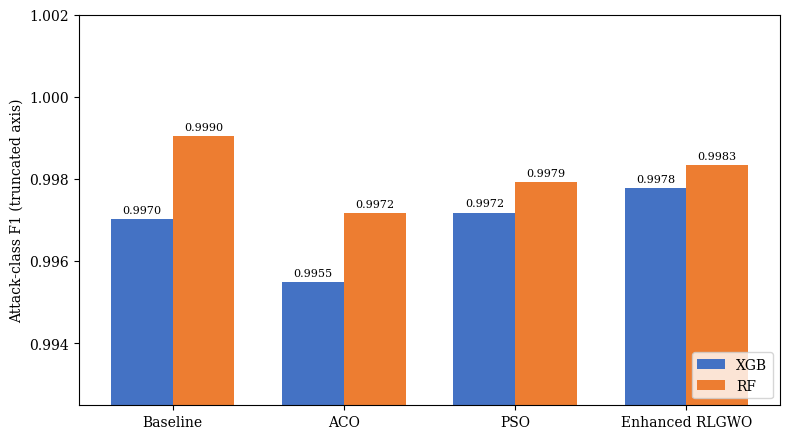

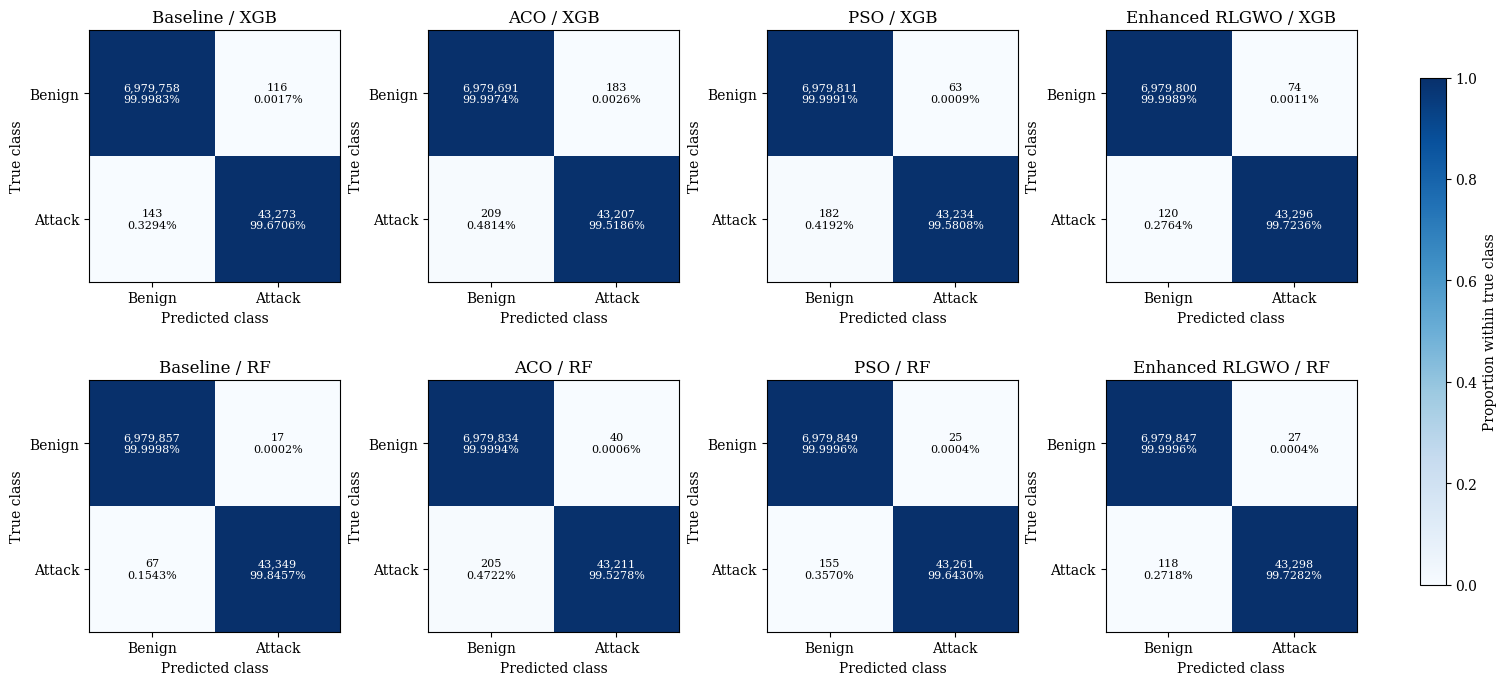

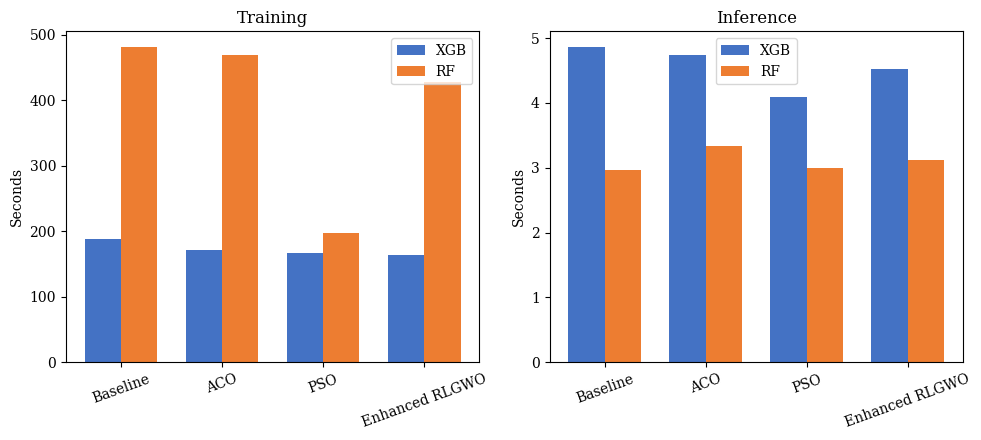

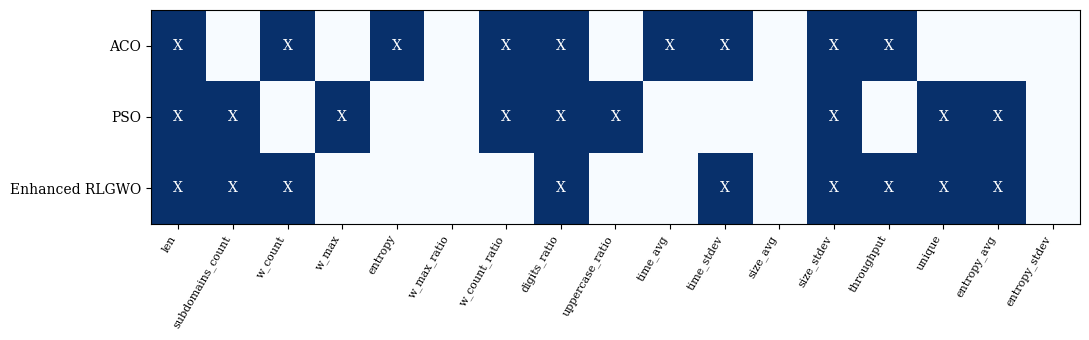

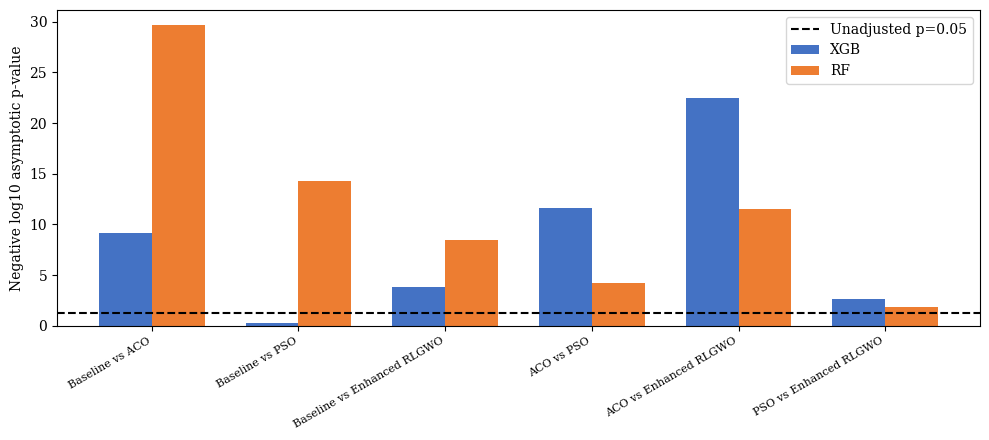

In [ ]:
plt.rcParams.update({'font.family':'serif','font.size':10,'pdf.fonttype':42})
colors={'xgb':'#4472C4','rf':'#ED7D31'}
names=list(configs)
x=np.arange(len(names)); width=0.36

def export(fig,name):
    fig.savefig(FIG_DIR/f'{name}.pdf',bbox_inches='tight')
    fig.savefig(FIG_DIR/f'{name}.png',dpi=300,bbox_inches='tight')
    plt.show(); plt.close(fig)

fig,ax=plt.subplots(figsize=(8,4.5))
for offset,key in [(-width/2,'xgb'),(width/2,'rf')]:
    values=metrics_df[metrics_df.Key==key].set_index('Configuration').loc[names,'F1']
    bars=ax.bar(x+offset,values,width,color=colors[key],label=key.upper())
    ax.bar_label(bars,fmt='%.4f',padding=3,fontsize=8)
ax.set_xticks(x,names); ax.set_ylabel('Attack-class F1 (truncated axis)')
ax.set_ylim(max(0,metrics_df.F1.min()-0.003),1.002)
ax.legend(loc='lower right'); fig.tight_layout(); export(fig,'f1_comparison')

fig,axes=plt.subplots(2,4,figsize=(15,7),constrained_layout=True)
for row,key in enumerate(['xgb','rf']):
    for col,name in enumerate(names):
        ax=axes[row,col]; cm=preds[name][key]['cm']; norm=cm/cm.sum(axis=1,keepdims=True)
        image=ax.imshow(norm,cmap='Blues',vmin=0,vmax=1)
        for i in range(2):
            for j in range(2):
                ax.text(j,i,f'{cm[i,j]:,}\n{100*norm[i,j]:.4f}%',ha='center',va='center',
                    color='white' if norm[i,j]>0.5 else 'black',fontsize=8)
        ax.set_xticks([0,1],['Benign','Attack']); ax.set_yticks([0,1],['Benign','Attack'])
        ax.set_xlabel('Predicted class'); ax.set_ylabel('True class'); ax.set_title(name+' / '+key.upper())
fig.colorbar(image,ax=axes.ravel().tolist(),fraction=0.02,label='Proportion within true class')
export(fig,'confusion_matrices_all')

fig,axes=plt.subplots(1,2,figsize=(10,4.5))
for ax,metric in zip(axes,['Training','Inference']):
    for offset,key in [(-width/2,'xgb'),(width/2,'rf')]:
        values=timing_df[timing_df.Key==key].set_index('Configuration').loc[names,metric]
        ax.bar(x+offset,values,width,label=key.upper(),color=colors[key])
    ax.set_xticks(x,names,rotation=20); ax.set_ylabel('Seconds'); ax.set_title(metric); ax.legend()
fig.tight_layout(); export(fig,'timing_comparison')

selected_names=names[1:]
matrix=np.zeros((3,17))
for i,name in enumerate(selected_names): matrix[i,configs[name]]=1
fig,ax=plt.subplots(figsize=(11,3.5)); ax.imshow(matrix,cmap='Blues',vmin=0,vmax=1,aspect='auto')
ax.set_yticks(range(3),selected_names)
ax.set_xticks(range(17),feature_names,rotation=60,ha='right',fontsize=8)
for i,j in zip(*np.where(matrix==1)): ax.text(j,i,'X',ha='center',va='center',color='white')
fig.tight_layout(); export(fig,'feature_selection')

fig,ax=plt.subplots(figsize=(10,4.5))
pairs=[a+' vs '+b for a,b in combinations(names,2)]
for offset,key in [(-width/2,'xgb'),(width/2,'rf')]:
    subset=mcnemar_df[mcnemar_df.Key==key]
    vals=-chi2.logsf(subset.chi2.to_numpy(),1)/np.log(10)
    ax.bar(np.arange(6)+offset,vals,width,label=key.upper(),color=colors[key])
ax.axhline(-np.log10(0.05),linestyle='--',color='black',label='Unadjusted p=0.05')
ax.set_xticks(range(6),pairs,rotation=30,ha='right',fontsize=8)
ax.set_ylabel('Negative log10 asymptotic p-value'); ax.legend()
fig.tight_layout(); export(fig,'mcnemar_significance')


## 10. Summary tables
These cells reload the saved outputs and print the tables used in the report.

**What this cell does:** Reloads saved McNemar results and search outputs so the summaries below work after a restart.

In [ ]:
from pathlib import Path
import json
import pandas as pd

RUN_DIR = Path.cwd() / "validation_only_run_v1"

if not RUN_DIR.exists():
    raise FileNotFoundError(
        f"Results folder not found: {RUN_DIR}\n"
        "Set RUN_DIR to the folder containing your saved experiment."
    )

feature_names = [
    "len",
    "subdomains_count",
    "w_count",
    "w_max",
    "entropy",
    "w_max_ratio",
    "w_count_ratio",
    "digits_ratio",
    "uppercase_ratio",
    "time_avg",
    "time_stdev",
    "size_avg",
    "size_stdev",
    "throughput",
    "unique",
    "entropy_avg",
    "entropy_stdev",
]

mcnemar_df = pd.read_csv(
    RUN_DIR / "mcnemar_results.csv"
)

search_results = {}

for name, filename in {
    "ACO": "aco_search.json",
    "PSO": "pso_search.json",
    "Enhanced RLGWO": "enhanced_rlgwo_search.json",
}.items():
    with open(
        RUN_DIR / filename,
        "r",
        encoding="utf-8",
    ) as file:
        search_results[name] = json.load(file)

print("Saved McNemar results and feature selections loaded.")

Saved McNemar results and feature selections loaded.


**What this cell does:** Builds the table of selected features and feature-reduction percentages for each optimiser.

In [ ]:
import pandas as pd

selection_rows = []

for name in ["ACO", "PSO", "Enhanced RLGWO"]:
    indices = [
        int(i)
        for i in search_results[name]["selected_indices"]
    ]

    selection_rows.append({
        "Optimiser": name,
        "Selected indices": ", ".join(map(str, indices)),
        "Selected features": ", ".join(
            feature_names[i] for i in indices
        ),
        "Number selected": len(indices),
        "Feature reduction (%)": (
            100 * (17 - len(indices)) / 17
        ),
    })

selection_df = pd.DataFrame(selection_rows)

print(selection_df.to_string(index=False))

selection_df.to_csv(
    RUN_DIR / "selected_feature_summary.csv",
    index=False,
)

     Optimiser               Selected indices                                                                                           Selected features  Number selected  Feature reduction (%)
           ACO   0, 2, 4, 6, 7, 9, 10, 12, 13            len, w_count, entropy, w_count_ratio, digits_ratio, time_avg, time_stdev, size_stdev, throughput                9              47.058824
           PSO   0, 1, 3, 6, 7, 8, 12, 14, 15 len, subdomains_count, w_max, w_count_ratio, digits_ratio, uppercase_ratio, size_stdev, unique, entropy_avg                9              47.058824
Enhanced RLGWO 0, 1, 2, 7, 10, 12, 13, 14, 15       len, subdomains_count, w_count, digits_ratio, time_stdev, size_stdev, throughput, unique, entropy_avg                9              47.058824


**What this cell does:** Prints the full McNemar results table for the report.

In [ ]:
columns = [
    "Classifier",
    "Config A",
    "Config B",
    "n01",
    "n10",
    "chi2",
    "p_asymptotic",
    "p_exact",
    "p_holm",
]

print(
    mcnemar_df[columns].to_string(
        index=False,
        float_format=lambda value: f"{value:.6g}",
    )
)

   Classifier Config A       Config B  n01  n10     chi2  p_asymptotic     p_exact      p_holm
      XGBoost Baseline            ACO  296  163  37.9608    7.2181e-10  5.5093e-10 3.85651e-09
      XGBoost Baseline            PSO  157  171 0.515244      0.472878    0.472933    0.472933
      XGBoost Baseline Enhanced RLGWO  110  175  14.3719   0.000150022 0.000141157 0.000564629
      XGBoost      ACO            PSO  144  291  49.0023   2.55663e-12 1.57963e-12 1.26371e-11
      XGBoost      ACO Enhanced RLGWO   98  296     98.5   3.25025e-23 3.29407e-24 3.62348e-23
      XGBoost      PSO Enhanced RLGWO  108  159   9.3633    0.00221374  0.00215469  0.00646406
Random Forest Baseline            ACO  178   17  131.282    2.1481e-30  5.1395e-35  6.1674e-34
Random Forest Baseline            PSO  122   26  60.9797   5.76655e-15 4.54768e-16 4.54768e-15
Random Forest Baseline Enhanced RLGWO   82   21  34.9515   3.38028e-09 1.06968e-09 6.41805e-09
Random Forest      ACO            PSO   95  160  1

## Reporting notes
- Use these NEW selected subsets and saved metrics, not previous hard-coded results.
- Report weighted-F1 search separately from attack-class final metrics.
- Report population/generation settings and actual search runtimes; equal generations are not equal evaluation budgets.
- Timings exclude feature extraction and search; do not describe them as end-to-end detection latency.
- This notebook relies on your original imported optimiser implementation and cached split provenance. A fresh independent holdout is strongest after prior test inspection.
- Preserve all outputs before restarting. Repeated-seed studies and grouped/temporal split audits are separate further work.